<a href="https://colab.research.google.com/github/cmd0850/machine_lerning/blob/main/%D0%94%D0%B6%D0%B5%D0%BD%D1%87%D0%B0%D0%BA%D0%BE_%D1%82%D1%80%D0%B5%D0%BD%D1%83%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D0%A0%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тренувальний ноутбук: лінійна регресія та регуляризація

**Курс:** Машинне навчання  
**Тема:** Linear Regression, Ridge, Lasso, Elastic Net

Цей ноутбук відповідає лекції про лінійну регресію та побудований як практичне продовження теоретичного матеріалу. У прикладах послідовно розглядаються проста й множинна лінійна регресія, метрики, залишки, недонавчання і перенавчання, L1/L2-регуляризація, Ridge, Lasso, Elastic Net, масштабування, крос-валідація, `GridSearchCV`, `Pipeline`, `ColumnTransformer` та навчальні криві.

У ноутбуці є два типи комірок:

- **Приклад** — готовий код, який потрібно виконати, проаналізувати та пояснити.
- **Самостійне завдання** — окрема кодова комірка з позначкою `TODO`. Її потрібно заповнити власноруч. Готового розв'язку в ноутбуці немає.

Рекомендація: виконувати комірки послідовно зверху вниз і після кожного блоку формулювати короткий висновок своїми словами.

## 0. Імпорт бібліотек і налаштування середовища

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Середовище готове до роботи.')

Середовище готове до роботи.


## 1. Проста лінійна регресія

Для однієї ознаки модель має вигляд

$$
\hat y = b_0 + b_1x.
$$

Тут $b_0$ — вільний член, а $b_1$ показує, на скільки одиниць у середньому змінюється прогноз $\hat y$ при збільшенні $x$ на одну одиницю.

Нижче згенеруємо дані, у яких істинна залежність приблизно дорівнює $y=5+2.4x$, але спостереження містять випадковий шум.

Вільний член b0: 4.907
Коефіцієнт b1: 2.451


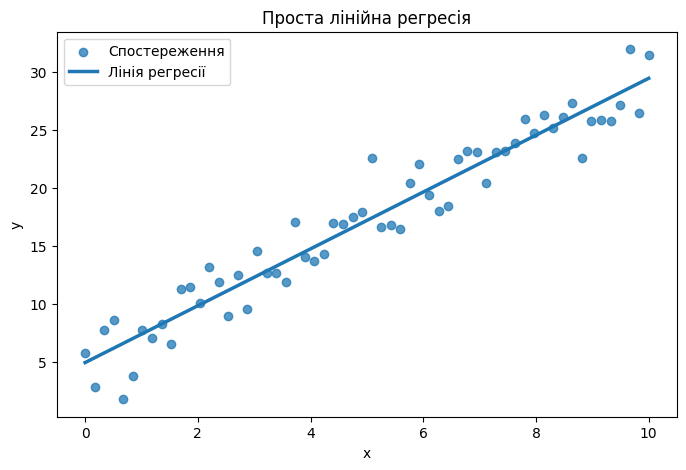

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

X_simple = np.linspace(0, 10, 60).reshape(-1, 1)
y_simple = 5 + 2.4 * X_simple.ravel() + rng.normal(0, 2.5, size=len(X_simple))

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)
y_simple_pred = simple_model.predict(X_simple)

print(f'Вільний член b0: {simple_model.intercept_:.3f}')
print(f'Коефіцієнт b1: {simple_model.coef_[0]:.3f}')

plt.figure(figsize=(8, 5))
plt.scatter(X_simple.ravel(), y_simple, alpha=0.75, label='Спостереження')
plt.plot(X_simple.ravel(), y_simple_pred, linewidth=2.5, label='Лінія регресії')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Проста лінійна регресія')
plt.legend()
plt.show()

**Що потрібно побачити.** Коефіцієнт нахилу має бути близьким до 2.4, але не обов'язково дорівнювати йому точно, оскільки дані містять шум. `fit()` оцінює параметри за навчальними даними, а `predict()` лише обчислює прогноз для заданих значень ознак.

### Самостійне завдання 1

1. Створіть новий масив `X_new` зі значеннями 2, 5 і 8.
2. Отримайте прогнози моделі.
3. Виведіть таблицю з колонками `x` та `prediction`.
4. Одним реченням поясніть зміст отриманого коефіцієнта `b1`.

In [3]:
# TODO: Самостійне завдання 1
# X_new = ...
# predictions = ...
# Створіть і виведіть DataFrame.

x=np.array([2,5,8]).reshape(-1,1)
y_pred=simple_model.predict(x)

tab=pd.DataFrame({
    "x":x.ravel(),
    "pred": y_pred
})
print(tab)

b1=simple_model.coef_[0]
print('\nb1: ', b1) #на скільки в середню змінюється у зі збільшенням х

   x       pred
0  2   9.809730
1  5  17.163214
2  8  24.516697

b1:  2.451161136674176


## 2. Метод найменших квадратів і ручний розрахунок коефіцієнтів

Для простої регресії коефіцієнт нахилу можна обчислити без готової моделі:

$$
b_1 = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2},
\qquad
b_0 = \bar y-b_1\bar x.
$$

Чисельник у формулі для $b_1$ відображає спільну зміну $x$ і $y$, а знаменник — варіативність самої ознаки $x$. Після знаходження нахилу вільний член підбирається так, щоб пряма проходила через точку $(\bar x, \bar y)$.

In [4]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([3.0, 5.2, 6.8, 9.1, 10.9])

x_bar = x.mean()
y_bar = y.mean()

b1_manual = ((x - x_bar) * (y - y_bar)).sum() / ((x - x_bar) ** 2).sum()
b0_manual = y_bar - b1_manual * x_bar

model_check = LinearRegression().fit(x.reshape(-1, 1), y)

print(f'Ручний розрахунок: b0={b0_manual:.4f}, b1={b1_manual:.4f}')
print(f'scikit-learn:     b0={model_check.intercept_:.4f}, b1={model_check.coef_[0]:.4f}')

Ручний розрахунок: b0=1.0900, b1=1.9700
scikit-learn:     b0=1.0900, b1=1.9700


### Самостійне завдання 2

Використайте масиви `x2 = [2, 4, 6, 8, 10]` та `y2 = [7, 11, 16, 19, 25]`. Власноруч обчисліть `b0` і `b1` за формулами, а потім перевірте результат за допомогою `LinearRegression`.

In [5]:
# TODO: Самостійне завдання 2
# x2 = ...
# y2 = ...
# Обчисліть середні, b1, b0 та порівняйте зі sklearn.
x2 = np.array([2, 4, 6, 8, 10], dtype=float)
y2 = np.array([7, 11, 16, 19, 25])

x_mean = x2.mean()
y_mean = y2.mean()

b1_manual = ((x2 - x_mean) * (y2 - y_mean)).sum() / ((x2 - x_mean) ** 2).sum()
b0_manual = y_mean - b1_manual * x_mean

model = LinearRegression().fit(x.reshape(-1, 1), y)

print('Вручну:\nb1: ', b1_manual.round(2), 'b0: ', b0_manual.round(2))
print('Scikit:\nb1: ', model.coef_[0].round(2), 'b0: ', model.intercept_.round(2))


Вручну:
b1:  2.2 b0:  2.4
Scikit:
b1:  1.97 b0:  1.09


## 3. Множинна лінійна регресія

У випадку кількох ознак модель має вигляд

$$
\hat y = b_0+b_1x_1+b_2x_2+\dots+b_px_p.
$$

Коефіцієнт $b_j$ інтерпретується як зміна прогнозу при збільшенні ознаки $x_j$ на одну одиницю **за інших рівних умов**, тобто при фіксованих значеннях інших ознак.

Для практики використаємо вбудований набір `diabetes`, тому ноутбук не потребує завантаження даних з Інтернету.

In [6]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

print('Розмір X:', X.shape)
print('Розмір y:', y.shape)
display(X.head())

Розмір X: (442, 10)
Розмір y: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [7]:
multi_model = LinearRegression()
multi_model.fit(X, y)

coef_table = pd.DataFrame({
    'feature': X.columns,
    'coefficient': multi_model.coef_
}).sort_values('coefficient', key=np.abs, ascending=False)

display(coef_table)
print(f'Intercept: {multi_model.intercept_:.3f}')

,feature,coefficient
4,s1,-792.175639
8,s5,751.273700
2,bmi,519.845920
5,s2,476.739021
3,bp,324.384646
1,sex,-239.815644
7,s4,177.063238
6,s3,101.043268
9,s6,67.626692
0,age,-10.009866


Intercept: 152.133


Зверніть увагу: великий за модулем коефіцієнт не завжди означає, що ознака є «найважливішою». Порівняння коефіцієнтів залежить від масштабу ознак та їх взаємної кореляції.

## 4. Train/test та наївний baseline

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)

print('Baseline RMSE:', root_mean_squared_error(y_test, baseline_pred))
print('LinearRegression RMSE:', root_mean_squared_error(y_test, linear_pred))

Baseline RMSE: 73.22249283682244
LinearRegression RMSE: 53.85344583676593


`DummyRegressor` не використовує закономірності в ознаках і в цьому прикладі прогнозує середнє значення цільової змінної з train. Якщо реальна модель не перевершує такий baseline, необхідно переглянути ознаки, постановку задачі або сам алгоритм.

## 5. Метрики якості регресії

У лекції розглядалися MAE, MSE, RMSE та $R^2$. Вони відповідають на різні питання.

- **MAE** показує середню абсолютну величину помилки.
- **MSE** сильніше штрафує великі помилки через піднесення залишку до квадрата.
- **RMSE** є коренем з MSE і вимірюється в тих самих одиницях, що й цільова змінна.
- **$R^2$** порівнює модель із прогнозом середнім значенням цільової змінної. На нових даних він може бути від'ємним.

In [9]:
def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
    }

metrics_baseline = regression_metrics(y_test, baseline_pred)
metrics_linear = regression_metrics(y_test, linear_pred)

pd.DataFrame([metrics_baseline, metrics_linear], index=['DummyRegressor', 'LinearRegression'])

,MAE,MSE,RMSE,R2
DummyRegressor,64.006461,5361.533457,73.222493,-0.011963
LinearRegression,42.794095,2900.193628,53.853446,0.452603


### Самостійне завдання 3

Обчисліть MAE, RMSE і $R^2$ окремо, **не використовуючи** функцію `regression_metrics`. Порівняйте `DummyRegressor` і `LinearRegression`. У Markdown-комірці нижче поясніть, яка модель краща і чому не варто робити висновок лише за однією метрикою.

In [10]:
# TODO: Самостійне завдання 3
# Обчисліть MAE, RMSE та R2 для baseline і LinearRegression.
MAE_dummy=mean_absolute_error(y_test, baseline_pred)
RMSE_dummy= root_mean_squared_error(y_test, baseline_pred)
R2_dummy = r2_score(y_test, baseline_pred)


MAE_linear=mean_absolute_error(y_test, linear_pred)
RMSE_linear = root_mean_squared_error(y_test, linear_pred)
R2_linear = r2_score(y_test, linear_pred)

comparison = pd.DataFrame(
    {
        'MAE': [MAE_dummy, MAE_linear],
        'RMSE': [RMSE_dummy, RMSE_linear],
        'R2': [R2_dummy, R2_linear],
    },
    index=['Dummy', 'Linear'],
)
comparison

,MAE,RMSE,R2
Dummy,64.006461,73.222493,-0.011963
Linear,42.794095,53.853446,0.452603


**Ваш висновок:**  
_Напишіть 2–4 речення після виконання розрахунків._

Лінійна прогресія виглядає значно кращою за dummy. Судячи з розрахунків, її похибка менша та даін місітять більше корисної інформації

## 6. Залишки та діагностика моделі

Залишок для об'єкта визначається як

$$
e_i = y_i-\hat y_i.
$$

Якщо модель добре описує систематичну частину залежності, на графіку `prediction → residual` не повинно бути вираженої структури. Дуга може вказувати на нелінійність, а «воронка» — на зміну дисперсії помилки.

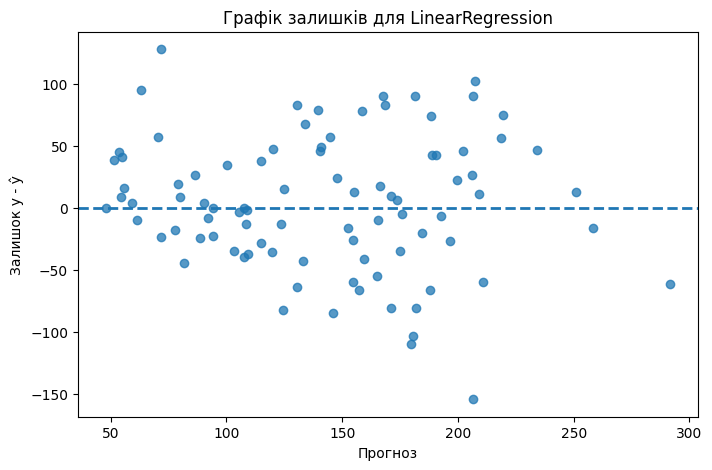

In [11]:
residuals = y_test - linear_pred

plt.figure(figsize=(8, 5))
plt.scatter(linear_pred, residuals, alpha=0.75)
plt.axhline(0, linestyle='--', linewidth=2)
plt.xlabel('Прогноз')
plt.ylabel('Залишок y - ŷ')
plt.title('Графік залишків для LinearRegression')
plt.show()

## 7. Недонавчання і перенавчання на поліноміальній регресії

Лінійна модель може недонавчатися, якщо реальна залежність нелінійна. Один зі способів збільшити гнучкість — створити поліноміальні ознаки. Але занадто високий ступінь полінома збільшує ризик перенавчання.

Порівняємо ступені 1, 4 і 15 на невеликій синтетичній вибірці.

In [12]:
rng = np.random.default_rng(RANDOM_STATE)
X_poly = np.sort(rng.uniform(-3, 3, 45)).reshape(-1, 1)
y_true_poly = np.sin(X_poly.ravel()) + 0.25 * X_poly.ravel()
y_poly = y_true_poly + rng.normal(0, 0.22, size=len(X_poly))

X_p_train, X_p_test, y_p_train, y_p_test = train_test_split(
    X_poly, y_poly, test_size=0.35, random_state=RANDOM_STATE
)

def fit_polynomial(degree):
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('reg', LinearRegression()),
    ])
    model.fit(X_p_train, y_p_train)
    train_pred = model.predict(X_p_train)
    test_pred = model.predict(X_p_test)
    return model, {
        'degree': degree,
        'train_rmse': root_mean_squared_error(y_p_train, train_pred),
        'test_rmse': root_mean_squared_error(y_p_test, test_pred),
    }

results = []
models_poly = {}
for degree in [1, 4, 15]:
    m, res = fit_polynomial(degree)
    models_poly[degree] = m
    results.append(res)

pd.DataFrame(results)

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,4,0.144969,0.203183
2,15,0.091024,0.244266


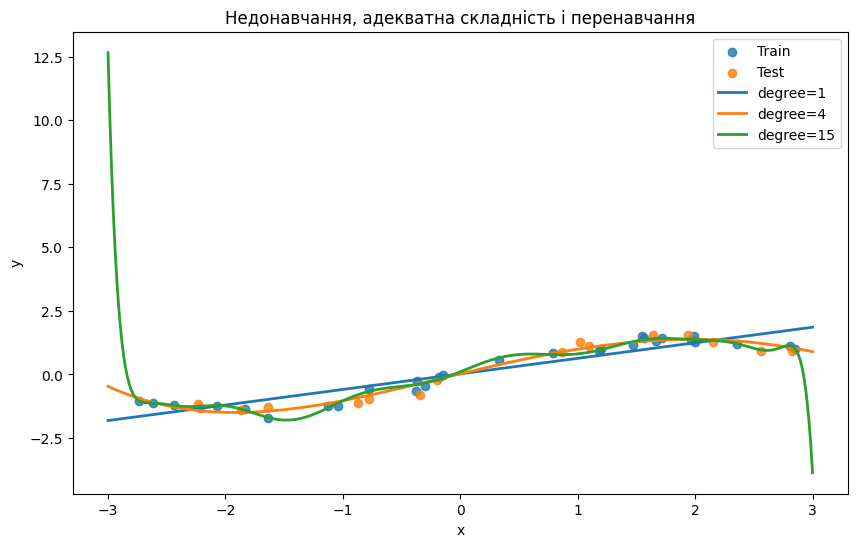

In [13]:
grid = np.linspace(-3, 3, 400).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_p_train, y_p_train, label='Train', alpha=0.8)
plt.scatter(X_p_test, y_p_test, label='Test', alpha=0.8)

for degree in [1, 4, 15]:
    plt.plot(grid, models_poly[degree].predict(grid), linewidth=2, label=f'degree={degree}')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Недонавчання, адекватна складність і перенавчання')
plt.legend()
plt.show()

### Самостійне завдання 4

1. Додайте до порівняння ступені 2, 6 і 10.
2. Побудуйте таблицю `degree`, `train_rmse`, `test_rmse`.
3. Визначте ступінь із найменшим `test_rmse`.
4. Поясніть, чому мінімальна train-помилка не гарантує найкращої моделі.

In [15]:
# TODO: Самостійне завдання 4
# Перевірте ступені 1, 2, 4, 6, 10, 15.
# Побудуйте таблицю результатів і зробіть висновок.


degrees = [1, 2, 4, 6, 10, 15]

results = []
models_poly = {}
for degree in degrees:
    m, res = fit_polynomial(degree)
    models_poly[degree] = m
    results.append(res)


results_df = pd.DataFrame(results)[['degree', 'train_rmse', 'test_rmse']]
display(results_df.round(4))


best_row = results_df.loc[results_df['test_rmse'].idxmin()]
best_degree = int(best_row['degree'])
print(f"Найкращий ступінь за тест рмсе: {best_degree} "
      f"(test_rmse = {best_row['test_rmse']:.4f}, train_rmse = {best_row['train_rmse']:.4f})")

#Трейн помилка вимірює, наскільки добре модель відтворбє дані з навчання, а не наскільки відтворює нові

,degree,train_rmse,test_rmse
0,1,0.3929,0.4654
1,2,0.3928,0.4640
2,4,0.1450,0.2032
3,6,0.1371,0.1963
4,10,0.1291,0.1918
5,15,0.0910,0.2443


Найкращий ступінь за test_rmse: 10 (test_rmse = 0.1918, train_rmse = 0.1291)


## 8. Регуляризація: загальна ідея

Коли модель має багато ознак або ознаки сильно корельовані, коефіцієнти можуть ставати нестабільними. Регуляризація додає до функції втрат штраф за великі коефіцієнти.

Для Ridge використовується L2-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p} b_j^2,
$$

для Lasso — L1-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p}|b_j|.
$$

Параметр $\alpha$ керує силою регуляризації. Якщо $\alpha=0$, штраф зникає. Надто велике $\alpha$ може надмірно стиснути коефіцієнти й спричинити недонавчання.

## 9. Чому перед Ridge, Lasso та Elastic Net потрібне масштабування

In [16]:
# Штучно змінюємо масштаби кількох ознак, щоб побачити роль StandardScaler.
X_scaled_demo = X.copy()
X_scaled_demo['bmi'] = X_scaled_demo['bmi'] * 1000
X_scaled_demo['bp'] = X_scaled_demo['bp'] * 0.01

Xsd_train, Xsd_test, ysd_train, ysd_test = train_test_split(
    X_scaled_demo, y, test_size=0.2, random_state=RANDOM_STATE
)

ridge_no_scaling = Ridge(alpha=10.0).fit(Xsd_train, ysd_train)
ridge_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(Xsd_train, ysd_train)

print('Ridge без масштабування RMSE:', root_mean_squared_error(ysd_test, ridge_no_scaling.predict(Xsd_test)))
print('Ridge + StandardScaler RMSE:', root_mean_squared_error(ysd_test, ridge_pipeline.predict(Xsd_test)))

Ridge без масштабування RMSE: 62.25349241861679
Ridge + StandardScaler RMSE: 53.626287568895194


Штраф застосовується безпосередньо до коефіцієнтів. Якщо ознаки вимірюються в дуже різних масштабах, одна й та сама величина коефіцієнта не має однакового змісту. Тому `StandardScaler` зазвичай включають у `Pipeline` перед регуляризованою лінійною моделлю.

## 10. Ridge-регресія: L2-регуляризація

In [17]:
ridge = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

print(regression_metrics(y_test, ridge_pred))

{'MAE': 42.81199941834889, 'MSE': 2892.0145657501726, 'RMSE': 53.777454065343896, 'R2': 0.45414652070698225}


## 11. Lasso: L1-регуляризація

In [18]:
lasso = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(alpha=1.0, max_iter=20000)),
])

lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)

lasso_coef = lasso.named_steps['reg'].coef_
print(regression_metrics(y_test, lasso_pred))
print('Кількість нульових коефіцієнтів:', np.sum(np.isclose(lasso_coef, 0)))

{'MAE': 42.80298373195777, 'MSE': 2824.568094049959, 'RMSE': 53.14666587896139, 'R2': 0.46687670944102466}
Кількість нульових коефіцієнтів: 1


На відміну від Ridge, Lasso може занулювати частину коефіцієнтів. Саме тому L1-регуляризацію іноді використовують як вбудований механізм відбору ознак. Проте при сильно корельованих предикторах вибір конкретної ознаки може бути нестабільним.

## 12. Elastic Net: поєднання L1 та L2

In [19]:
elastic = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000)),
])

elastic.fit(X_train, y_train)
elastic_pred = elastic.predict(X_test)

print(regression_metrics(y_test, elastic_pred))

{'MAE': 42.873332243316874, 'MSE': 2866.4612552977674, 'RMSE': 53.539343060013046, 'R2': 0.4589695819678379}


В Elastic Net параметр `alpha` визначає загальну силу регуляризації, а `l1_ratio` — співвідношення між L1 та L2. Значення `l1_ratio=1` наближає модель до Lasso, а `l1_ratio=0` — до Ridge.

### Самостійне завдання 5

Навчіть на одному й тому самому train/test розбитті чотири моделі: `LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`. Для регуляризованих моделей використайте `StandardScaler` у `Pipeline`. Побудуйте таблицю з MAE, RMSE та $R^2$.

In [20]:
# TODO: Самостійне завдання 5
# Побудуйте й порівняйте чотири моделі.


X, y = load_diabetes(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Pipeline([
        ('scale', StandardScaler()),
        ('reg', Ridge(alpha=1.0)),
    ]),
    'Lasso': Pipeline([
        ('scale', StandardScaler()),
        ('reg', Lasso(alpha=0.5, max_iter=10000)),
    ]),
    'ElasticNet': Pipeline([
        ('scale', StandardScaler()),
        ('reg', ElasticNet(alpha=0.5, l1_ratio=0.5, max_iter=10000)),
    ]),
}


rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        'model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': root_mean_squared_error(y_test, pred),
        'R2': r2_score(y_test, pred),
    })

metrics_df = pd.DataFrame(rows).set_index('model')
display(metrics_df.round(4))


,MAE,RMSE,R2
model,,,
LinearRegression,42.7941,53.8534,0.4526
Ridge,42.8120,53.7775,0.4541
Lasso,42.8395,53.4556,0.4607
ElasticNet,43.1991,53.3798,0.4622


## 13. Крос-валідація

Одне train/test розбиття залежить від випадкового поділу. K-fold cross-validation кілька разів змінює validation-частину і дає більш стійку оцінку якості моделі. Важливо, що preprocessing повинен бути всередині `Pipeline`, щоб на кожному фолді параметри масштабування оцінювалися лише з train-частини.

In [21]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_cv_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

scores = cross_validate(
    ridge_cv_model,
    X,
    y,
    cv=cv,
    scoring={
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
    },
    return_train_score=True,
)

cv_table = pd.DataFrame({
    'fold': np.arange(1, 6),
    'train_R2': scores['train_r2'],
    'val_R2': scores['test_r2'],
    'val_MAE': -scores['test_mae'],
    'val_RMSE': -scores['test_rmse'],
})

display(cv_table)
print('Середній validation RMSE:', cv_table['val_RMSE'].mean())

,fold,train_R2,val_R2,val_MAE,val_RMSE
0,1,0.527632,0.454147,42.811999,53.777454
1,2,0.497124,0.571674,41.616638,51.692906
2,3,0.538901,0.391921,47.224871,57.530264
3,4,0.494045,0.583169,42.166318,52.966248
4,5,0.540152,0.394449,47.397540,58.168400


Середній validation RMSE: 54.827054212084306


## 14. Підбір alpha для Ridge за GridSearchCV

In [22]:
ridge_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge()),
])

param_grid_ridge = {
    'reg__alpha': np.logspace(-3, 3, 13)
}

ridge_search = GridSearchCV(
    ridge_search_model,
    param_grid=param_grid_ridge,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

ridge_search.fit(X_train, y_train)

print('Найкраще alpha:', ridge_search.best_params_['reg__alpha'])
print('CV RMSE:', -ridge_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, ridge_search.predict(X_test)))

Найкраще alpha: 1.0
CV RMSE: 55.374175368673455
Test RMSE: 53.777454065343896


Тестову вибірку не використовують для підбору `alpha`. Гіперпараметр обирається всередині train за крос-валідацією, а test використовується лише після завершення вибору моделі.

## 15. Підбір alpha і l1_ratio для Elastic Net

In [23]:
elastic_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid_elastic = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}

elastic_search = GridSearchCV(
    elastic_search_model,
    param_grid=param_grid_elastic,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

elastic_search.fit(X_train, y_train)

print('Найкращі параметри:', elastic_search.best_params_)
print('CV RMSE:', -elastic_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, elastic_search.predict(X_test)))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test RMSE: 53.74450007977087


### Самостійне завдання 6

Виконайте `GridSearchCV` для Lasso. Перевірте не менше 10 значень `alpha` у логарифмічній шкалі. Порівняйте найкращий Lasso з найкращим Ridge за однаковою схемою CV.

In [25]:
# TODO: Самостійне завдання 6
# 1. Створіть Pipeline(StandardScaler -> Lasso).
# 2. Задайте сітку alpha.
# 3. Запустіть GridSearchCV.
# 4. Порівняйте CV RMSE та test RMSE з Ridge.

# Єдина схема для обох моделей
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


alphas = np.logspace(-3, 1, 15)
param_grid = {'reg__alpha': alphas}

lasso_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(max_iter=20000)),
])
ridge_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge()),
])


lasso_gs = GridSearchCV(
    lasso_pipe, param_grid, cv=cv,
    scoring='neg_root_mean_squared_error', n_jobs=-1,
)
ridge_gs = GridSearchCV(
    ridge_pipe, param_grid, cv=cv,
    scoring='neg_root_mean_squared_error', n_jobs=-1,
)

lasso_gs.fit(X_train, y_train)
ridge_gs.fit(X_train, y_train)


comparison = []
for name, gs in [('Lasso', lasso_gs), ('Ridge', ridge_gs)]:
    test_pred = gs.best_estimator_.predict(X_test)
    comparison.append({
        'model': name,
        'best_alpha': gs.best_params_['reg__alpha'],
        'cv_rmse': -gs.best_score_,
        'test_rmse': root_mean_squared_error(y_test, test_pred),
        'test_r2': r2_score(y_test, test_pred),
    })

display(pd.DataFrame(comparison).set_index('model').round(4))





best_lasso_coef = pd.Series(
    lasso_gs.best_estimator_.named_steps['reg'].coef_, index=X.columns
)
print('Обнулені Lasso ознаки:', list(best_lasso_coef[best_lasso_coef == 0].index))

,best_alpha,cv_rmse,test_rmse,test_r2
model,,,,
Lasso,0.1000,55.3540,53.7087,0.4555
Ridge,0.7197,55.3744,53.7935,0.4538


Обнулені Lasso ознаки: []


Різниці майже немає, тому при виборі треба керуватися не точністю

## 16. Як регуляризація змінює коефіцієнти

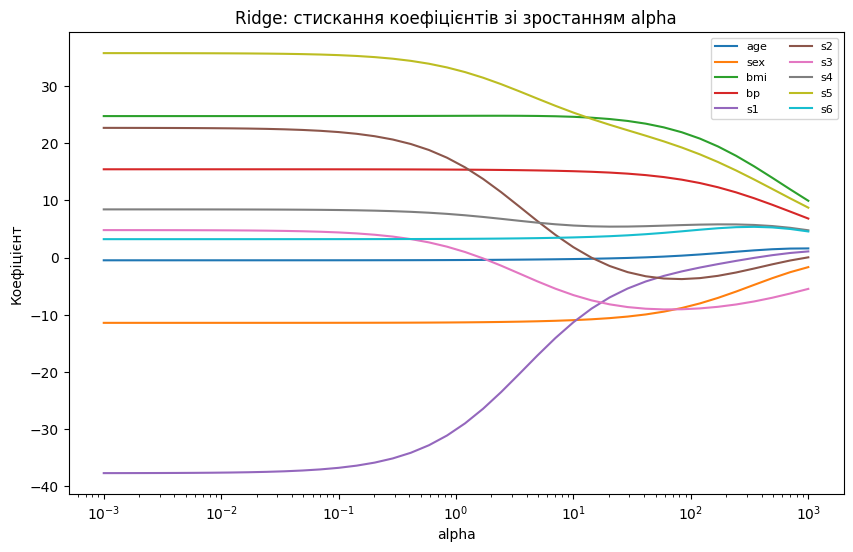

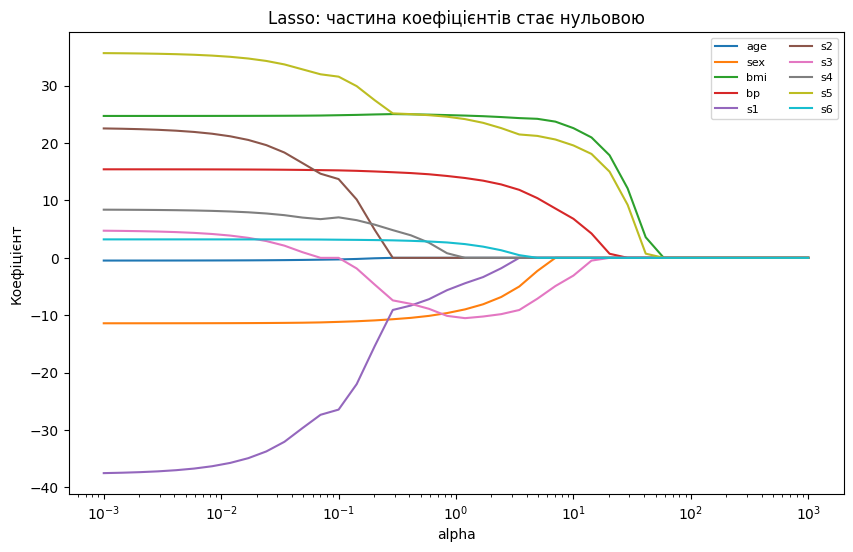

In [26]:
alphas = np.logspace(-3, 3, 40)
ridge_paths = []
lasso_paths = []

X_for_path = StandardScaler().fit_transform(X)

for alpha in alphas:
    ridge_m = Ridge(alpha=alpha).fit(X_for_path, y)
    lasso_m = Lasso(alpha=alpha, max_iter=30000).fit(X_for_path, y)
    ridge_paths.append(ridge_m.coef_)
    lasso_paths.append(lasso_m.coef_)

ridge_paths = np.array(ridge_paths)
lasso_paths = np.array(lasso_paths)

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, ridge_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Ridge: стискання коефіцієнтів зі зростанням alpha')
plt.legend(ncol=2, fontsize=8)
plt.show()

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, lasso_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Lasso: частина коефіцієнтів стає нульовою')
plt.legend(ncol=2, fontsize=8)
plt.show()

Ці графіки демонструють ключову різницю. Ridge плавно стискає коефіцієнти до нуля, тоді як Lasso може зробити частину з них точно нульовими.

## 17. Мультиколінеарність і стабільність коефіцієнтів

In [27]:
rng = np.random.default_rng(RANDOM_STATE)
n = 250
x1 = rng.normal(size=n)
x2 = x1 + rng.normal(scale=0.03, size=n)  # дуже сильна кореляція
x3 = rng.normal(size=n)
y_corr = 5 * x1 + 5 * x2 + 0.5 * x3 + rng.normal(scale=1.5, size=n)

X_corr = pd.DataFrame({'x1': x1, 'x2': x2, 'x3': x3})
print(X_corr.corr())

ols_corr = LinearRegression().fit(X_corr, y_corr)
ridge_corr = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(X_corr, y_corr)

coef_compare = pd.DataFrame({
    'feature': X_corr.columns,
    'OLS': ols_corr.coef_,
    'Ridge_scaled': ridge_corr.named_steps['reg'].coef_,
})
coef_compare

          x1        x2        x3
x1  1.000000  0.999515 -0.008921
x2  0.999515  1.000000 -0.010420
x3 -0.008921 -0.010420  1.000000


,feature,OLS,Ridge_scaled
0,x1,5.446248,4.546617
1,x2,4.410887,4.534370
2,x3,0.444792,0.439193


За наявності дуже корельованих ознак окремі коефіцієнти OLS можуть бути нестабільними: невеликі зміни даних здатні суттєво змінити їх значення. Ridge зменшує variance коефіцієнтів завдяки L2-штрафу.

## 18. Категоріальні ознаки, пропуски та ColumnTransformer

У реальній табличній задачі дані часто містять числові й категоріальні ознаки, а також пропуски. Їх потрібно обробляти всередині `Pipeline`, щоб не створювати витік інформації.

In [28]:
rng = np.random.default_rng(RANDOM_STATE)
n = 300

housing = pd.DataFrame({
    'area': rng.normal(75, 20, n).clip(25, 150),
    'rooms': rng.integers(1, 6, n),
    'age': rng.integers(0, 70, n).astype(float),
    'district': rng.choice(['center', 'north', 'south'], n, p=[0.3, 0.35, 0.35]),
})

# Додаємо кілька пропусків.
housing.loc[rng.choice(n, 18, replace=False), 'age'] = np.nan

price = (
    1500 * housing['area']
    + 7000 * housing['rooms']
    - 500 * housing['age'].fillna(housing['age'].median())
    + housing['district'].map({'center': 40000, 'north': 12000, 'south': 0})
    + rng.normal(0, 12000, n)
)

X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    housing, price, test_size=0.2, random_state=RANDOM_STATE
)

numeric_features = ['area', 'rooms', 'age']
categorical_features = ['district']

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
])

housing_model = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=1.0)),
])

housing_model.fit(X_h_train, y_h_train)
housing_pred = housing_model.predict(X_h_test)

print('Housing RMSE:', root_mean_squared_error(y_h_test, housing_pred))
print('Housing R2:', r2_score(y_h_test, housing_pred))

Housing RMSE: 10925.278371503928
Housing R2: 0.9068908686435069


### Самостійне завдання 7

Додайте до таблиці `housing` нову категоріальну ознаку `condition` зі значеннями `new`, `good`, `needs_repair`. Включіть її в `ColumnTransformer`, перенавчіть модель і перевірте, чи змінилася test-помилка.

In [30]:
# TODO: Самостійне завдання 7
# Створіть ознаку condition, додайте її до categorical_features,
# побудуйте новий Pipeline та оцініть модель.


rng_c = np.random.default_rng(RANDOM_STATE + 1)
housing['condition'] = rng_c.choice(['new', 'good', 'needs_repair'], n, p=[0.25, 0.5, 0.25])


condition_effect = housing['condition'].map({'new': 15000, 'good': 0, 'needs_repair': -25000})
price_c = price + condition_effect


X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    housing, price_c, test_size=0.2, random_state=RANDOM_STATE
)


def build_model(num_cols, cat_cols):
    prep = ColumnTransformer([
        ('num', numeric_pipe, num_cols),
        ('cat', categorical_pipe, cat_cols),
    ])
    return Pipeline([('prep', prep), ('reg', Ridge(alpha=1.0))])

variants = {
    'без condition': ['district'],
    'з condition':   ['district', 'condition'],
}

rows = []
fitted = {}
for name, cat_cols in variants.items():
    model = build_model(numeric_features, cat_cols)
    model.fit(X_h_train, y_h_train)
    pred = model.predict(X_h_test)
    fitted[name] = model
    rows.append({
        'model': name,
        'MAE': mean_absolute_error(y_h_test, pred),
        'RMSE': root_mean_squared_error(y_h_test, pred),
        'R2': r2_score(y_h_test, pred),
    })

cmp_df = pd.DataFrame(rows).set_index('model')
display(cmp_df.round(4))

delta = cmp_df.loc['з condition', 'RMSE'] - cmp_df.loc['без condition', 'RMSE']
print(f'Зміна test RMSE: {delta:,.0f} ({delta / cmp_df.loc["без condition", "RMSE"]:.1%})')


prep = fitted['з condition'].named_steps['prep']
feat_names = prep.get_feature_names_out()
coefs = pd.Series(fitted['з condition'].named_steps['reg'].coef_, index=feat_names)
display(coefs.filter(like='condition').round(0))

,MAE,RMSE,R2
model,,,
без condition,16016.3489,19180.3415,0.7543
з condition,8714.6746,10875.5695,0.9210


Зміна test RMSE: -8,305 (-43.3%)


,0
cat__condition_good,3747.0
cat__condition_needs_repair,-21991.0
cat__condition_new,18244.0


## 19. Навчальні криві

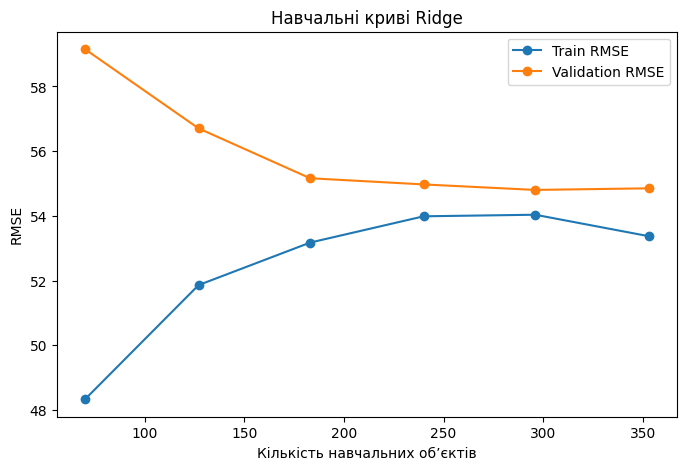

In [31]:
learning_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=ridge_search.best_params_['reg__alpha'])),
])

train_sizes, train_scores, val_scores = learning_curve(
    learning_model,
    X,
    y,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1,
)

train_rmse_curve = -train_scores.mean(axis=1)
val_rmse_curve = -val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse_curve, marker='o', label='Train RMSE')
plt.plot(train_sizes, val_rmse_curve, marker='o', label='Validation RMSE')
plt.xlabel('Кількість навчальних об’єктів')
plt.ylabel('RMSE')
plt.title('Навчальні криві Ridge')
plt.legend()
plt.show()

Якщо train і validation помилки високі та близькі, це ознака можливого недонавчання. Якщо train-помилка значно нижча за validation, це може свідчити про високу variance та перенавчання. Навчальні криві допомагають зрозуміти, чи може збільшення обсягу даних бути корисним.

## 20. Повний приклад: коректний вибір моделі без використання test

In [32]:
# 1. Test відкладаємо один раз.
X_final_train, X_final_test, y_final_train, y_final_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# 2. Вибір моделі відбувається тільки всередині train за CV.
model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.5, 0.9],
}

search = GridSearchCV(
    model,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
)
search.fit(X_final_train, y_final_train)

# 3. Лише після завершення підбору оцінюємо test.
final_pred = search.predict(X_final_test)

print('Найкращі параметри:', search.best_params_)
print('CV RMSE:', -search.best_score_)
print('Test metrics:', regression_metrics(y_final_test, final_pred))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test metrics: {'MAE': 42.81393247843441, 'MSE': 2888.4712888244917, 'RMSE': 53.74450007977087, 'R2': 0.4548152967432053}


# 21. Підсумкове практичне завдання для самостійної роботи

Виконайте повний експеримент на наборі `diabetes`. Цей блок потрібно зробити **самостійно**, використовуючи попередні приклади лише як орієнтир.

Вимоги до роботи:

1. Завантажити `load_diabetes(as_frame=True)` і переглянути структуру даних.
2. Відкласти 20% даних у test із `random_state=42`.
3. Побудувати `DummyRegressor` і `LinearRegression` як baseline.
4. Обчислити MAE, RMSE та $R^2$ на test.
5. Побудувати Ridge, Lasso та Elastic Net через `Pipeline` із `StandardScaler`.
6. Виконати 5-fold cross-validation.
7. Для Ridge і Lasso підібрати `alpha`; для Elastic Net — `alpha` та `l1_ratio`.
8. Порівняти моделі в одній таблиці.
9. Для найкращої моделі побудувати графік `фактичні значення → прогноз` та графік залишків.
10. Проаналізувати коефіцієнти найкращої лінійної моделі.
11. Сформулювати підсумковий висновок: яка модель обрана, за якою метрикою та чому.

Нижче залишені окремі комірки для кожного етапу.

### Крок 1. Дані

In [33]:
# TODO: Завантажте diabetes, сформуйте X_task та y_task, виведіть shape і перші рядки.
diabetes = load_diabetes(as_frame=True)
X_task = diabetes.data
y_task = diabetes.target

print('X_task shape:', X_task.shape)
print('y_task shape:', y_task.shape)

display(X_task.head())
display(y_task.head())

X_task shape: (442, 10)
y_task shape: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0


### Крок 2. Train/test

In [34]:
# TODO: Виконайте train_test_split з test_size=0.2 та random_state=42.
X_task_train, X_task_test, y_task_train, y_task_test = train_test_split(
    X_task, y_task, test_size=0.2, random_state=42
)

print('Train:', X_task_train.shape, y_task_train.shape)
print('Test: ', X_task_test.shape, y_task_test.shape)

Train: (353, 10) (353,)
Test:  (89, 10) (89,)


### Крок 3. Baseline

In [35]:
# TODO: Навчіть DummyRegressor та LinearRegression.
# Отримайте прогнози на test.

dummy = DummyRegressor(strategy='mean')
dummy.fit(X_task_train, y_task_train)
dummy_pred = dummy.predict(X_task_test)


lin_reg = LinearRegression()
lin_reg.fit(X_task_train, y_task_train)
lin_pred = lin_reg.predict(X_task_test)

print('Dummy: перші 5 прогнозів ', dummy_pred[:5].round(1))
print('Linear: перші 5 прогнозів ', lin_pred[:5].round(1))
print('Справжні значення', y_task_test.values[:5])

Dummy: перші 5 прогнозів  [153.7 153.7 153.7 153.7 153.7]
Linear: перші 5 прогнозів  [139.5 179.5 134.  291.4 123.8]
Справжні значення [219.  70. 202. 230. 111.]


### Крок 4. Метрики

In [37]:
# TODO: Обчисліть MAE, RMSE та R2 для baseline-моделей.
# Збережіть результати в DataFrame.

predictions = {
    'DummyRegressor': dummy_pred,
    'LinearRegression': lin_pred,
}

baseline_rows = []
for name, pred in predictions.items():
    baseline_rows.append({
        'model': name,
        'MAE': mean_absolute_error(y_task_test, pred),
        'RMSE': root_mean_squared_error(y_task_test, pred),
        'R2': r2_score(y_task_test, pred),
    })

baseline_df = pd.DataFrame(baseline_rows).set_index('model')
display(baseline_df.round(4))

,MAE,RMSE,R2
model,,,
DummyRegressor,64.0065,73.2225,-0.0120
LinearRegression,42.7941,53.8534,0.4526


### Крок 5. Ridge, Lasso, Elastic Net

In [38]:
# TODO: Створіть три Pipeline зі StandardScaler і відповідною моделлю.
pipelines = {
    'Ridge': Pipeline([
        ('scale', StandardScaler()),
        ('reg', Ridge(alpha=1.0)),
    ]),
    'Lasso': Pipeline([
        ('scale', StandardScaler()),
        ('reg', Lasso(alpha=0.1, max_iter=20000)),
    ]),
    'ElasticNet': Pipeline([
        ('scale', StandardScaler()),
        ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000)),
    ]),
}


pipe_preds = {}
for name, pipe in pipelines.items():
    pipe.fit(X_task_train, y_task_train)
    pipe_preds[name] = pipe.predict(X_task_test)

for name, pred in pipe_preds.items():
    print(f'{name}: перші 5 прогнозів', pred[:5].round(1))

Ridge: перші 5 прогнозів [139.9 180.  135.7 292.1 123.2]
Lasso: перші 5 прогнозів [140.2 180.3 137.  291.4 122.8]
ElasticNet: перші 5 прогнозів [142.1 179.7 141.3 290.4 123.3]


### Крок 6. Крос-валідація

In [42]:
# TODO: Створіть KFold(n_splits=5, shuffle=True, random_state=42)
# та порівняйте моделі за CV RMSE.
from sklearn.model_selection import KFold, cross_val_score

cv5 = KFold(n_splits=5, shuffle=True, random_state=42)


all_models = {
    'DummyRegressor': dummy,
    'LinearRegression': lin_reg,
    **pipelines,
}

cv_rows = []
for name, model in all_models.items():
    scores = cross_val_score(
        model, X_task_train, y_task_train,
        cv=cv5, scoring='neg_root_mean_squared_error', n_jobs=-1,
    )
    rmse_folds = -scores
    cv_rows.append({
        'model': name,
        'cv_rmse_mean': rmse_folds.mean(),
        'cv_rmse_std': rmse_folds.std(),
    })

cv_df = pd.DataFrame(cv_rows).set_index('model').sort_values('cv_rmse_mean')
display(cv_df.round(3))

,cv_rmse_mean,cv_rmse_std
model,,
Lasso,55.354,2.356
Ridge,55.374,2.373
LinearRegression,55.395,2.361
ElasticNet,55.433,2.351
DummyRegressor,78.134,5.638


### Крок 7. Підбір гіперпараметрів

In [43]:
# TODO: Виконайте GridSearchCV:
# Ridge -> alpha
# Lasso -> alpha
# ElasticNet -> alpha + l1_ratio

alphas = np.logspace(-3, 1, 15)
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]

search_spaces = {
    'Ridge': (
        Pipeline([('scale', StandardScaler()), ('reg', Ridge())]),
        {'reg__alpha': alphas},
    ),
    'Lasso': (
        Pipeline([('scale', StandardScaler()), ('reg', Lasso(max_iter=20000))]),
        {'reg__alpha': alphas},
    ),
    'ElasticNet': (
        Pipeline([('scale', StandardScaler()), ('reg', ElasticNet(max_iter=20000))]),
        {'reg__alpha': alphas, 'reg__l1_ratio': l1_ratios},
    ),
}

grid_results = {}
grid_rows = []
for name, (pipe, grid) in search_spaces.items():
    gs = GridSearchCV(
        pipe, grid, cv=cv5,
        scoring='neg_root_mean_squared_error', n_jobs=-1,
    )
    gs.fit(X_task_train, y_task_train)
    grid_results[name] = gs

    i = gs.best_index_
    grid_rows.append({
        'model': name,
        'best_params': {k.replace('reg__', ''): round(float(v), 4) for k, v in gs.best_params_.items()},
        'cv_rmse': -gs.best_score_,
        'cv_rmse_std': gs.cv_results_['std_test_score'][i],
    })

grid_df = pd.DataFrame(grid_rows).set_index('model')
display(grid_df)

,best_params,cv_rmse,cv_rmse_std
model,,,
Ridge,{'alpha': 0.7197},55.374408,2.372398
Lasso,{'alpha': 0.1},55.353958,2.355868
ElasticNet,"{'alpha': 0.1, 'l1_ratio': 1.0}",55.353958,2.355868


### Крок 8. Фінальна таблиця моделей

In [44]:
# TODO: Побудуйте таблицю, де рядки — моделі,
# а стовпці — CV RMSE, test MAE, test RMSE, test R2.

final_rows = []


for name in ['DummyRegressor', 'LinearRegression']:
    model = all_models[name]
    pred = model.predict(X_task_test)
    final_rows.append({
        'model': name,
        'CV RMSE': cv_df.loc[name, 'cv_rmse_mean'],
        'test MAE': mean_absolute_error(y_task_test, pred),
        'test RMSE': root_mean_squared_error(y_task_test, pred),
        'test R2': r2_score(y_task_test, pred),
    })


for name, gs in grid_results.items():
    pred = gs.best_estimator_.predict(X_task_test)
    final_rows.append({
        'model': f'{name} (tuned)',
        'CV RMSE': -gs.best_score_,
        'test MAE': mean_absolute_error(y_task_test, pred),
        'test RMSE': root_mean_squared_error(y_task_test, pred),
        'test R2': r2_score(y_task_test, pred),
    })

final_df = pd.DataFrame(final_rows).set_index('model').sort_values('CV RMSE')
display(final_df.round(4))

,CV RMSE,test MAE,test RMSE,test R2
model,,,,
Lasso (tuned),55.3540,42.8052,53.7087,0.4555
ElasticNet (tuned),55.3540,42.8052,53.7087,0.4555
Ridge (tuned),55.3744,42.8079,53.7935,0.4538
LinearRegression,55.3946,42.7941,53.8534,0.4526
DummyRegressor,78.1336,64.0065,73.2225,-0.0120


### Крок 9. Візуалізація найкращої моделі

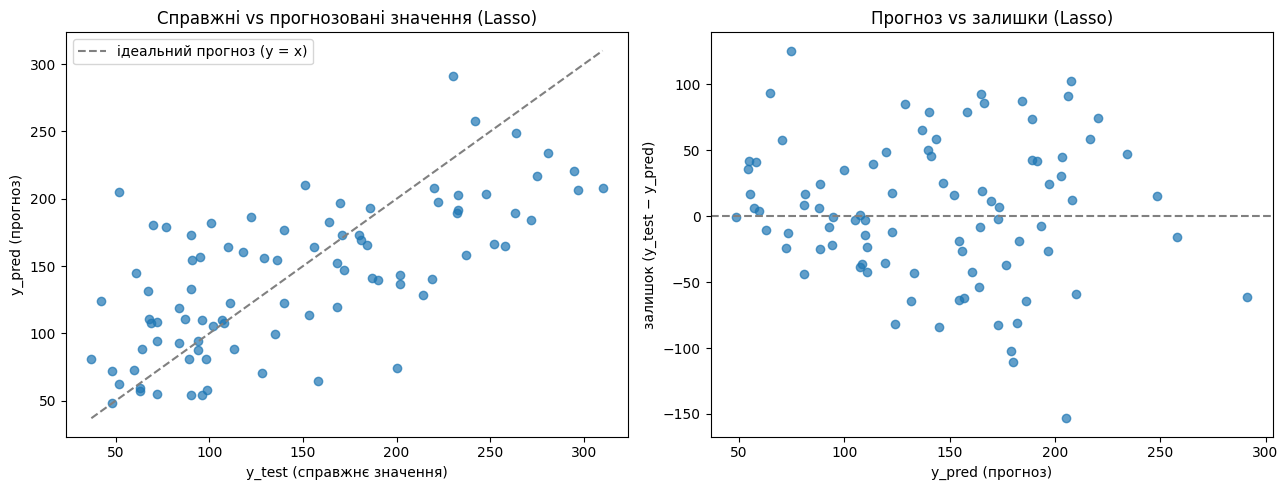

In [45]:
# TODO: Побудуйте два графіки:
# 1) y_test проти y_pred;
# 2) prediction проти residual.


best_name = min(grid_results, key=lambda k: -grid_results[k].best_score_)
best_model = grid_results[best_name].best_estimator_

y_pred = best_model.predict(X_task_test)
residuals = y_task_test.values - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))


ax = axes[0]
ax.scatter(y_task_test, y_pred, alpha=0.7)
lims = [min(y_task_test.min(), y_pred.min()), max(y_task_test.max(), y_pred.max())]
ax.plot(lims, lims, linestyle='--', color='gray', label='ідеальний прогноз (y = x)')
ax.set_xlabel('y_test (справжнє значення)')
ax.set_ylabel('y_pred (прогноз)')
ax.set_title(f'Справжні vs прогнозовані значення ({best_name})')
ax.legend()


ax = axes[1]
ax.scatter(y_pred, residuals, alpha=0.7)
ax.axhline(0, linestyle='--', color='gray')
ax.set_xlabel('y_pred (прогноз)')
ax.set_ylabel('залишок (y_test − y_pred)')
ax.set_title(f'Прогноз vs залишки ({best_name})')

plt.tight_layout()
plt.show()

### Крок 10. Коефіцієнти

Модель: Lasso, інтерсепт = 153.74


,feature,coef,abs_coef
0,s5,29.633,29.633
1,s1,-29.358,29.358
2,bmi,25.825,25.825
3,bp,16.644,16.644
4,s2,13.276,13.276
5,sex,-11.316,11.316
6,s4,10.236,10.236
7,s6,2.393,2.393
8,age,1.730,1.730
9,s3,0.548,0.548


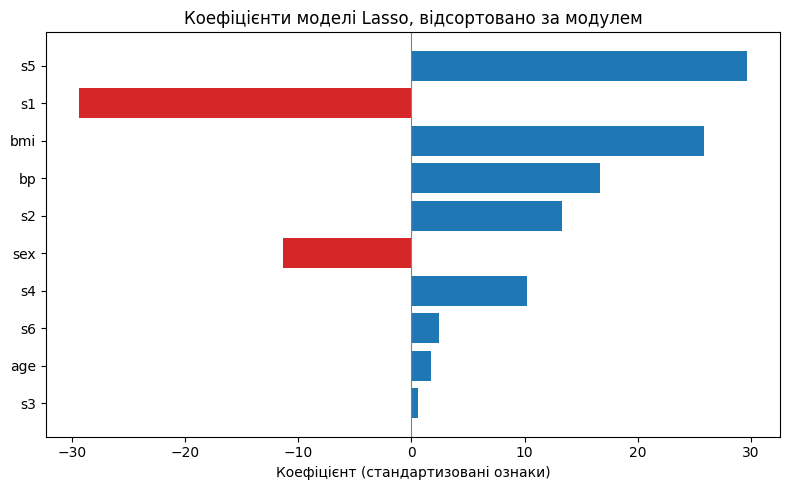

In [46]:
# TODO: Витягніть коефіцієнти найкращої моделі,
# зіставте їх із назвами ознак та відсортуйте за модулем.


reg = best_model.named_steps['reg']

coef_df = pd.DataFrame({
    'feature': X_task.columns,
    'coef': reg.coef_,
})
coef_df['abs_coef'] = coef_df['coef'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False).reset_index(drop=True)

print(f'Модель: {best_name}, інтерсепт = {reg.intercept_:.2f}')
display(coef_df.round(3))


plt.figure(figsize=(8, 5))
plot_df = coef_df.iloc[::-1]
colors = ['tab:red' if c < 0 else 'tab:blue' for c in plot_df['coef']]
plt.barh(plot_df['feature'], plot_df['coef'], color=colors)
plt.axvline(0, color='gray', linewidth=0.8)
plt.xlabel('Коефіцієнт (стандартизовані ознаки)')
plt.title(f'Коефіцієнти моделі {best_name}, відсортовано за модулем')
plt.tight_layout()
plt.show()

### Крок 11. Підсумковий висновок

У новій Markdown-комірці після цієї сформулюйте висновок обсягом 5–8 речень. Обов'язково зазначте:

- яка модель показала найкращий результат;
- за якою метрикою виконано вибір;
- чи є ознаки перенавчання;
- як регуляризація вплинула на результат;
- чому test не використовувався під час підбору гіперпараметрів.

Найкращою виявилась Лассо з підібраним альфа близько 0.1. Ознак перенавчання немає, всі моделі кращі. Регуляризація майже не вплинула на результат: альфа малий, лассо не обнулила жодну ознаку

## Контрольні питання після практики

1. Чому `StandardScaler` для Ridge/Lasso/Elastic Net доцільно розміщувати всередині `Pipeline`?
2. Чим відрізняється train-помилка від validation/test-помилки?
3. За якими ознаками можна розпізнати перенавчання?
4. Чим L1-регуляризація відрізняється від L2-регуляризації?
5. Чому `alpha` не можна підбирати за тестовою вибіркою?
6. Яку роль відіграє `l1_ratio` в Elastic Net?
7. Чому великий за модулем коефіцієнт не завжди означає, що ознака є найважливішою?
8. У чому перевага крос-валідації порівняно з одним випадковим validation-розбиттям?